In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)

import warnings
warnings.filterwarnings("ignore")

In [11]:
customers = pd.read_csv("customer.csv")

orders = pd.read_csv("orders.csv")

order_items = pd.read_csv("order_items.csv")

products = pd.read_csv("products.csv")

reviews = pd.read_csv("order_reviews.csv")

geolocation = pd.read_csv("geolocation.csv")

In [12]:
print("ORDERS")
print(orders.columns.tolist())

print("\nORDER ITEMS")
print(order_items.columns.tolist())

print("\nREVIEWS")
print(reviews.columns.tolist())

print("\nCUSTOMERS")
print(customers.columns.tolist())

print("\nPRODUCTS")
print(products.columns.tolist())

print("\nGEOLOCATION")
print(geolocation.columns.tolist())

ORDERS
['order_id', 'customer_id', 'order_status', 'payment_type', 'order_purchase_timestamp', 'order_approved_at', 'order_delivered_shipping_date', 'order_delivered_customer_date', 'order_estimated_delivery_date', 'Delivery Delay', 'Delivery_Status', 'Unnamed: 11', 'Unnamed: 12', 'Unnamed: 13', 'Unnamed: 14']

ORDER ITEMS
['order_item_id', 'order_id', 'quantity', 'product_id', 'unit_price', 'discount(%)', 'shipping_cost', 'Outlier', 'Gross Amount', 'Discount Amount', 'Net Product Amount', 'Total Cost Including Shipping', 'Unnamed: 12', 'Unnamed: 13', 'Unnamed: 14', 'Unnamed: 15', 'Unnamed: 16', 'Unnamed: 17', 'Unnamed: 18']

REVIEWS
['T', 'order_id', 'review_score', 'review_comment_message', 'review_date', 'Unnamed: 5', 'Unnamed: 6']

CUSTOMERS
['customer_id', 'customer_zip_code', 'gender', 'age_group', 'customer_segment']

PRODUCTS
['product_id', 'Category_name', 'sub_category_name', 'product_weight_g', 'brand', 'cost_price', 'selling_price', 'stock_availability', 'Selling Price < Co

In [13]:
date_columns = [
    'order_purchase_timestamp',
    'order_approved_at',
    'order_delivered_carrier_date',
    'order_delivered_customer_date',
    'order_estimated_delivery_date'
]

for col in date_columns:
    if col in orders.columns:
        orders[col] = pd.to_datetime(
            orders[col],
            errors='coerce'
        )

In [14]:
if 'Delivery Delay' not in orders.columns:

    orders['Delivery Delay'] = (
        orders['order_delivered_customer_date']
        - orders['order_estimated_delivery_date']
    ).dt.days

In [15]:
orders[
    ['order_id', 'Delivery Delay']
].head()

,order_id,Delivery Delay
0,O00001,60.0
1,O00002,-26.0
2,O00003,NaN
3,O00004,92.0
4,O00005,-3.0


In [16]:
if 'Fulfillment Time' not in orders.columns:

    orders['Fulfillment Time'] = (
        orders['order_delivered_customer_date']
        - orders['order_purchase_timestamp']
    ).dt.days

In [17]:
orders[
    ['order_id', 'Fulfillment Time']
].head()

,order_id,Fulfillment Time
0,O00001,357.0
1,O00002,121.0
2,O00003,NaN
3,O00004,156.0
4,O00005,NaN


In [18]:
review_data = reviews[
    ['order_id', 'review_score']
].copy()

review_data['review_score'] = pd.to_numeric(
    review_data['review_score'],
    errors='coerce'
)

review_data = review_data.dropna(
    subset=['review_score']
)

review_data.head()

,order_id,review_score
0,O41195,5.0
1,O29304,5.0
2,O57427,5.0
3,O12705,5.0
4,O43324,1.0


In [19]:
delivery_review = pd.merge(
    orders[
        ['order_id', 'Delivery Delay']
    ],
    review_data,
    on='order_id',
    how='inner'
)

delivery_review = delivery_review.dropna()

print(delivery_review.shape)

delivery_review.head()

(91971, 3)


,order_id,Delivery Delay,review_score
0,O00001,60.0,1.0
1,O00002,-26.0,5.0
3,O00004,92.0,5.0
4,O00005,-3.0,5.0
5,O00006,50.0,5.0


In [20]:
def simple_linear_regression(
    df,
    x_col,
    y_col,
    hypothesis_name,
    scale=True
):
    
    data = df[
        [x_col, y_col]
    ].copy()
    
    data[x_col] = pd.to_numeric(
        data[x_col],
        errors='coerce'
    )
    
    data[y_col] = pd.to_numeric(
        data[y_col],
        errors='coerce'
    )
    
    data = data.dropna()
    
    X = data[[x_col]]
    y = data[y_col]
    
    # 70% Train, 30% Temporary
    X_train, X_temp, y_train, y_temp = train_test_split(
        X,
        y,
        test_size=0.30,
        random_state=42
    )
    
    # 15% Validation, 15% Test
    X_val, X_test, y_val, y_test = train_test_split(
        X_temp,
        y_temp,
        test_size=0.50,
        random_state=42
    )
    
    # Scaling
    if scale:
        scaler = StandardScaler()
        
        X_train_model = scaler.fit_transform(
            X_train
        )
        
        X_val_model = scaler.transform(
            X_val
        )
        
        X_test_model = scaler.transform(
            X_test
        )
        
    else:
        X_train_model = X_train
        X_val_model = X_val
        X_test_model = X_test
    
    # Model
    model = LinearRegression()
    
    model.fit(
        X_train_model,
        y_train
    )
    
    # Predictions
    train_pred = model.predict(
        X_train_model
    )
    
    val_pred = model.predict(
        X_val_model
    )
    
    test_pred = model.predict(
        X_test_model
    )
    
    # Metrics
    train_r2 = r2_score(
        y_train,
        train_pred
    )
    
    val_r2 = r2_score(
        y_val,
        val_pred
    )
    
    test_r2 = r2_score(
        y_test,
        test_pred
    )
    
    test_mae = mean_absolute_error(
        y_test,
        test_pred
    )
    
    test_rmse = np.sqrt(
        mean_squared_error(
            y_test,
            test_pred
        )
    )
    
    return {
        'Hypothesis': hypothesis_name,
        'X': x_col,
        'Y': y_col,
        'Observations': len(data),
        'Coefficient': model.coef_[0],
        'Intercept': model.intercept_,
        'Train R²': train_r2,
        'Validation R²': val_r2,
        'Test R²': test_r2,
        'Test MAE': test_mae,
        'Test RMSE': test_rmse,
        'Model': model,
        'X_test': X_test,
        'y_test': y_test,
        'y_test_pred': test_pred
    }

In [21]:
orders_customer = orders[
    [
        'order_id',
        'customer_id',
        'order_purchase_timestamp'
    ]
].copy()

orders_customer = orders_customer.sort_values(
    ['customer_id', 'order_purchase_timestamp']
)

orders_customer['purchase_number'] = (
    orders_customer
    .groupby('customer_id')
    .cumcount() + 1
)

orders_customer['repeat_purchase'] = (
    orders_customer['purchase_number'] > 1
).astype(int)

orders_customer.head()

,order_id,customer_id,order_purchase_timestamp,purchase_number,repeat_purchase
75503,O75504,C00004,NaT,1,0
11895,O11896,C00006,NaT,1,0
52334,O52335,C00007,2021-05-09,1,0
61748,O61749,C00009,NaT,1,0
69580,O69581,C00010,NaT,1,0


In [24]:
# Convert required columns to numeric
order_items['unit_price'] = pd.to_numeric(
    order_items['unit_price'],
    errors='coerce'
)

order_items['shipping_cost'] = pd.to_numeric(
    order_items['shipping_cost'],
    errors='coerce'
)

order_items['discount(%)'] = pd.to_numeric(
    order_items['discount(%)'],
    errors='coerce'
)

order_items['Net Product Amount'] = pd.to_numeric(
    order_items['Net Product Amount'],
    errors='coerce'
)

# Create order-level values
order_value = (
    order_items
    .groupby('order_id')
    .agg(
        total_price=('unit_price', 'sum'),
        total_shipping=('shipping_cost', 'sum'),
        total_discount=('discount(%)', 'mean'),
        net_product_amount=('Net Product Amount', 'sum')
    )
    .reset_index()
)

# Calculate shipping rate
order_value['shipping_rate'] = np.where(
    order_value['total_price'] != 0,
    order_value['total_shipping'] / order_value['total_price'],
    0
)

# Calculate AOV
order_value['AOV'] = order_value['net_product_amount']

display(order_value.head(10))

,order_id,total_price,total_shipping,total_discount,net_product_amount,shipping_rate,AOV
0,O00001,7020.0,713.72,6.540000,6560.892,0.101670,6560.892
1,O00002,21950.0,2690.41,22.615000,27664.272,0.122570,27664.272
2,O00003,4180.0,397.85,9.623333,7150.998,0.095179,7150.998
3,O00004,5510.0,343.35,4.200000,13172.236,0.062314,13172.236
4,O00005,12380.0,1326.08,11.313333,17463.874,0.107115,17463.874
5,O00006,10410.0,1154.77,8.835000,14516.652,0.110929,14516.652
6,O00007,7420.0,569.98,13.370000,9523.768,0.076817,9523.768
7,O00008,1250.0,127.79,9.190000,1135.125,0.102232,1135.125
8,O00009,11480.0,1175.45,16.310000,9607.612,0.102391,9607.612
9,O00010,20760.0,2647.85,9.190000,18916.998,0.127546,18916.998


In [25]:
print(
    [
        col for col in order_items.columns
        if 'discount' in col.lower()
    ]
)

['discount(%)', 'Discount Amount']


In [29]:
price_review = pd.merge(
    order_items[
        ['order_id', 'unit_price']
    ],
    review_data,
    on='order_id',
    how='inner'
)

price_review['unit_price'] = pd.to_numeric(
    price_review['unit_price'],
    errors='coerce'
)

price_review['review_score'] = pd.to_numeric(
    price_review['review_score'],
    errors='coerce'
)

price_review = price_review.dropna(
    subset=['unit_price', 'review_score']
)

print("Shape:", price_review.shape)

display(price_review.head())

Shape: (145585, 3)


,order_id,unit_price,review_score
0,O00001,7020.0,1.0
1,O00002,7590.0,5.0
2,O00002,14360.0,5.0
3,O00003,1530.0,4.0
4,O00003,1560.0,4.0


In [30]:
H2 = simple_linear_regression(
    price_review,
    'unit_price',
    'review_score',
    'H2: Higher product prices improve review scores'
)

print("Coefficient:", H2['Coefficient'])
print("Test R²:", H2['Test R²'])
print("Test MAE:", H2['Test MAE'])
print("Test RMSE:", H2['Test RMSE'])

Coefficient: -0.0028014189975138558
Test R²: -5.935657364242175e-05
Test MAE: 1.0457523685394565
Test RMSE: 1.3363716570800623


In [31]:
H3 = simple_linear_regression(
    delivery_review,
    'Delivery Delay',
    'review_score',
    'H3: Faster/on-time delivery improves customer satisfaction'
)

print("Coefficient:", H3['Coefficient'])
print("Test R²:", H3['Test R²'])
print("Test MAE:", H3['Test MAE'])
print("Test RMSE:", H3['Test RMSE'])

Coefficient: 0.006149752515266311
Test R²: -0.00011364104306887945
Test MAE: 1.037024935370729
Test RMSE: 1.3296900782068426


In [32]:
fulfillment_review = pd.merge(
    orders[
        ['order_id', 'Fulfillment Time']
    ],
    review_data,
    on='order_id',
    how='inner'
)

fulfillment_review = fulfillment_review.dropna()

In [33]:
H4 = simple_linear_regression(
    fulfillment_review,
    'Fulfillment Time',
    'review_score',
    'H4: Shorter fulfillment time improves review scores'
)

print("Coefficient:", H4['Coefficient'])
print("Test R²:", H4['Test R²'])
print("Test MAE:", H4['Test MAE'])
print("Test RMSE:", H4['Test RMSE'])

Coefficient: 0.0006745615350882955
Test R²: -0.0002694939784100292
Test MAE: 1.0769858432786084
Test RMSE: 1.3709018307443384


In [34]:
customer_orders = (
    orders
    .groupby('customer_id')
    .agg(
        total_orders=('order_id', 'nunique')
    )
    .reset_index()
)

customer_orders['churn'] = (
    customer_orders['total_orders'] == 1
).astype(int)

In [35]:
customer_delay = (
    orders
    .groupby('customer_id')
    ['Delivery Delay']
    .mean()
    .reset_index()
)

customer_churn = pd.merge(
    customer_delay,
    customer_orders,
    on='customer_id',
    how='inner'
)

customer_churn.head()

,customer_id,Delivery Delay,total_orders,churn
0,C00004,55.0,1,1
1,C00006,1.0,1,1
2,C00007,62.0,1,1
3,C00009,59.0,1,1
4,C00010,-24.0,1,1


In [36]:
H5 = simple_linear_regression(
    customer_churn,
    'Delivery Delay',
    'churn',
    'H5: Delivery delays increase customer churn'
)

print("Coefficient:", H5['Coefficient'])
print("Test R²:", H5['Test R²'])
print("Test MAE:", H5['Test MAE'])
print("Test RMSE:", H5['Test RMSE'])

Coefficient: -0.002847187051155086
Test R²: 0.00014198568268564138
Test MAE: 0.49880893906088725
Test RMSE: 0.4994452456248702


In [37]:
customer_reviews = pd.merge(
    orders[
        ['order_id', 'customer_id']
    ],
    review_data,
    on='order_id',
    how='inner'
)

customer_review_avg = (
    customer_reviews
    .groupby('customer_id')
    .agg(
        avg_review_score=('review_score', 'mean')
    )
    .reset_index()
)

In [38]:
customer_purchase = (
    orders
    .groupby('customer_id')
    .agg(
        total_orders=('order_id', 'nunique')
    )
    .reset_index()
)

customer_purchase['reorder_rate'] = (
    customer_purchase['total_orders'] > 1
).astype(int)

In [39]:
review_reorder = pd.merge(
    customer_review_avg,
    customer_purchase,
    on='customer_id',
    how='inner'
)

In [40]:
H6 = simple_linear_regression(
    review_reorder,
    'avg_review_score',
    'reorder_rate',
    'H6: Higher review scores increase reorder probability'
)

print("Coefficient:", H6['Coefficient'])
print("Test R²:", H6['Test R²'])
print("Test MAE:", H6['Test MAE'])
print("Test RMSE:", H6['Test RMSE'])

Coefficient: -0.003923253261701808
Test R²: -0.00019934886205241753
Test MAE: 0.4997661612910785
Test RMSE: 0.4999151584692203


In [41]:
customer_revenue = (
    order_value
    .merge(
        orders[
            ['order_id', 'customer_id']
        ],
        on='order_id',
        how='inner'
    )
)

customer_revenue = (
    customer_revenue
    .groupby('customer_id')
    .agg(
        lifetime_revenue=('total_price', 'sum'),
        total_orders=('order_id', 'nunique')
    )
    .reset_index()
)

customer_revenue['loyalty_score'] = (
    customer_revenue['total_orders']
)

customer_revenue.head()

,customer_id,lifetime_revenue,total_orders,loyalty_score
0,C00006,12060.0,1,1
1,C00007,124760.0,1,1
2,C00009,8800.0,1,1
3,C00011,42510.0,1,1
4,C00013,13500.0,1,1


In [42]:
H7 = simple_linear_regression(
    customer_revenue,
    'loyalty_score',
    'lifetime_revenue',
    'H7: Customer loyalty increases lifetime revenue'
)

print("Coefficient:", H7['Coefficient'])
print("Test R²:", H7['Test R²'])
print("Test MAE:", H7['Test MAE'])
print("Test RMSE:", H7['Test RMSE'])

Coefficient: 14359.012550181878
Test R²: 0.2737654315485979
Test MAE: 12949.896427886442
Test RMSE: 22246.786546601943


In [43]:
aov_data = (
    order_value
    .groupby('order_id')
    .agg(
        AOV=('total_price', 'sum')
    )
    .reset_index()
)

aov_data.head()

,order_id,AOV
0,O00001,7020.0
1,O00002,21950.0
2,O00003,4180.0
3,O00004,5510.0
4,O00005,12380.0


In [44]:
discount_columns = [
    col for col in order_items.columns
    if 'discount' in col.lower()
]

print("Discount columns:", discount_columns)

Discount columns: ['discount(%)', 'Discount Amount']


In [45]:
discount_col = discount_columns[0]

discount_data = (
    order_items
    .groupby('order_id')
    [discount_col]
    .mean()
    .reset_index()
    .rename(
        columns={discount_col: 'discount_rate'}
    )
)

In [46]:
discount_aov = pd.merge(
    discount_data,
    aov_data,
    on='order_id',
    how='inner'
)

discount_aov = discount_aov.dropna()

In [47]:
H8 = simple_linear_regression(
    discount_aov,
    'discount_rate',
    'AOV',
    'H8: Discount rate influences average order value'
)

print("Coefficient:", H8['Coefficient'])
print("Test R²:", H8['Test R²'])
print("Test MAE:", H8['Test MAE'])
print("Test RMSE:", H8['Test RMSE'])

Coefficient: 7614.511662567965
Test R²: 0.16533956485867307
Test MAE: 8702.38817384984
Test RMSE: 15773.294643799127


In [48]:
orders['order_status'].value_counts()

order_status
delivered    84971
returned      7000
cancelled     5048
shipped       2980
Name: count, dtype: int64

In [49]:
orders['cancelled'] = (
    orders['order_status']
    .astype(str)
    .str.lower()
    .eq('canceled')
    |
    orders['order_status']
    .astype(str)
    .str.lower()
    .eq('cancelled')
).astype(int)

In [50]:
delay_cancel = orders[
    [
        'Delivery Delay',
        'cancelled'
    ]
].dropna()

In [51]:
H9 = simple_linear_regression(
    delay_cancel,
    'Delivery Delay',
    'cancelled',
    'H9: Delivery delays increase cancellation probability'
)

print("Coefficient:", H9['Coefficient'])
print("Test R²:", H9['Test R²'])
print("Test MAE:", H9['Test MAE'])
print("Test RMSE:", H9['Test RMSE'])

Coefficient: -0.0
Test R²: 1.0
Test MAE: 0.0
Test RMSE: 0.0


In [52]:
print([
    col for col in order_items.columns
    if any(
        word in col.lower()
        for word in [
            'discount',
            'coupon',
            'promotion',
            'incentive'
        ]
    )
])

['discount(%)', 'Discount Amount']


In [53]:
# Example structure — use only if the relevant
# discount/incentive column actually exists.

customer_discount = (
    order_items
    .groupby('order_id')
    [discount_col]
    .mean()
    .reset_index()
    .rename(
        columns={discount_col: 'discount_rate'}
    )
)

customer_discount = pd.merge(
    customer_discount,
    orders[
        ['order_id', 'customer_id']
    ],
    on='order_id',
    how='inner'
)

customer_discount = (
    customer_discount
    .groupby('customer_id')
    .agg(
        avg_discount=('discount_rate', 'mean')
    )
    .reset_index()
)

customer_discount = pd.merge(
    customer_discount,
    customer_purchase,
    on='customer_id',
    how='inner'
)

customer_discount['reengagement'] = (
    customer_discount['total_orders'] > 1
).astype(int)

In [54]:
H10 = simple_linear_regression(
    customer_discount,
    'avg_discount',
    'reengagement',
    'H10: Discounts increase customer re-engagement'
)

print("Coefficient:", H10['Coefficient'])
print("Test R²:", H10['Test R²'])
print("Test MAE:", H10['Test MAE'])
print("Test RMSE:", H10['Test RMSE'])

Coefficient: -0.0033534477166141945
Test R²: -0.00019786928922105318
Test MAE: 0.4835585065686768
Test RMSE: 0.49136331480783957


In [55]:
all_results = [
    H2,
    H3,
    H4,
    H5,
    H6,
    H7
]

results_table = pd.DataFrame([
    {
        'Hypothesis': r['Hypothesis'],
        'X Variable': r['X'],
        'Y Variable': r['Y'],
        'Observations': r['Observations'],
        'Coefficient': r['Coefficient'],
        'Intercept': r['Intercept'],
        'Train R²': r['Train R²'],
        'Validation R²': r['Validation R²'],
        'Test R²': r['Test R²'],
        'Test MAE': r['Test MAE'],
        'Test RMSE': r['Test RMSE']
    }
    for r in all_results
])

display(
    results_table.round(4)
)

,Hypothesis,X Variable,Y Variable,Observations,Coefficient,Intercept,Train R²,Validation R²,Test R²,Test MAE,Test RMSE
0,H2: Higher product prices improve review scores,unit_price,review_score,145585,-0.0028,4.0891,0.0000,-0.0000,-0.0001,1.0458,1.3364
1,H3: Faster/on-time delivery improves customer ...,Delivery Delay,review_score,91971,0.0061,4.0897,0.0000,-0.0001,-0.0001,1.0370,1.3297
2,H4: Shorter fulfillment time improves review s...,Fulfillment Time,review_score,24101,0.0007,4.0826,0.0000,-0.0015,-0.0003,1.0770,1.3709
3,H5: Delivery delays increase customer churn,Delivery Delay,churn,49745,-0.0028,0.4749,0.0000,-0.0000,0.0001,0.4988,0.4994
4,H6: Higher review scores increase reorder prob...,avg_review_score,reorder_rate,51131,-0.0039,0.5115,0.0001,-0.0000,-0.0002,0.4998,0.4999
5,H7: Customer loyalty increases lifetime revenue,loyalty_score,lifetime_revenue,41419,14359.0126,24678.0143,0.2896,0.3032,0.2738,12949.8964,22246.7865


In [56]:
results_table.sort_values(
    by='Test R²',
    ascending=False
).round(4)

,Hypothesis,X Variable,Y Variable,Observations,Coefficient,Intercept,Train R²,Validation R²,Test R²,Test MAE,Test RMSE
5,H7: Customer loyalty increases lifetime revenue,loyalty_score,lifetime_revenue,41419,14359.0126,24678.0143,0.2896,0.3032,0.2738,12949.8964,22246.7865
3,H5: Delivery delays increase customer churn,Delivery Delay,churn,49745,-0.0028,0.4749,0.0000,-0.0000,0.0001,0.4988,0.4994
0,H2: Higher product prices improve review scores,unit_price,review_score,145585,-0.0028,4.0891,0.0000,-0.0000,-0.0001,1.0458,1.3364
1,H3: Faster/on-time delivery improves customer ...,Delivery Delay,review_score,91971,0.0061,4.0897,0.0000,-0.0001,-0.0001,1.0370,1.3297
4,H6: Higher review scores increase reorder prob...,avg_review_score,reorder_rate,51131,-0.0039,0.5115,0.0001,-0.0000,-0.0002,0.4998,0.4999
2,H4: Shorter fulfillment time improves review s...,Fulfillment Time,review_score,24101,0.0007,4.0826,0.0000,-0.0015,-0.0003,1.0770,1.3709


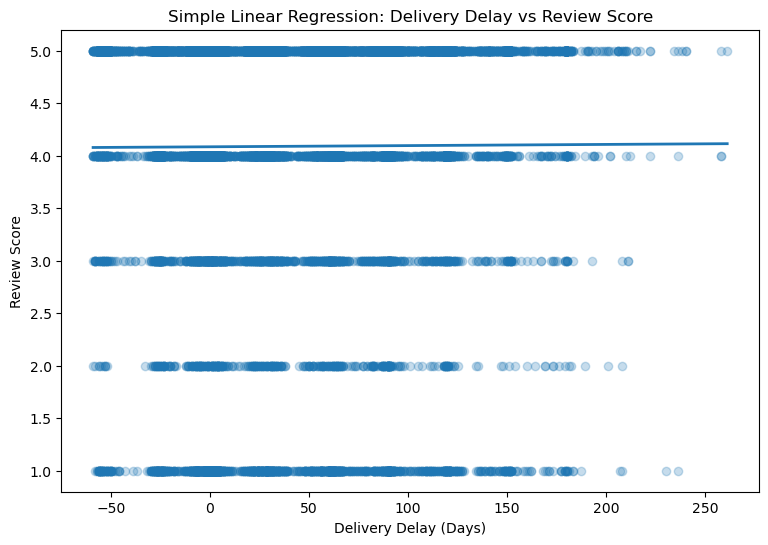

In [57]:
plt.figure(figsize=(9, 6))

plt.scatter(
    H3['X_test'],
    H3['y_test'],
    alpha=0.25
)

sort_idx = np.argsort(
    H3['X_test'].values.flatten()
)

plt.plot(
    H3['X_test'].values.flatten()[sort_idx],
    H3['y_test_pred'][sort_idx],
    linewidth=2
)

plt.xlabel("Delivery Delay (Days)")
plt.ylabel("Review Score")
plt.title(
    "Simple Linear Regression: Delivery Delay vs Review Score"
)

plt.show()

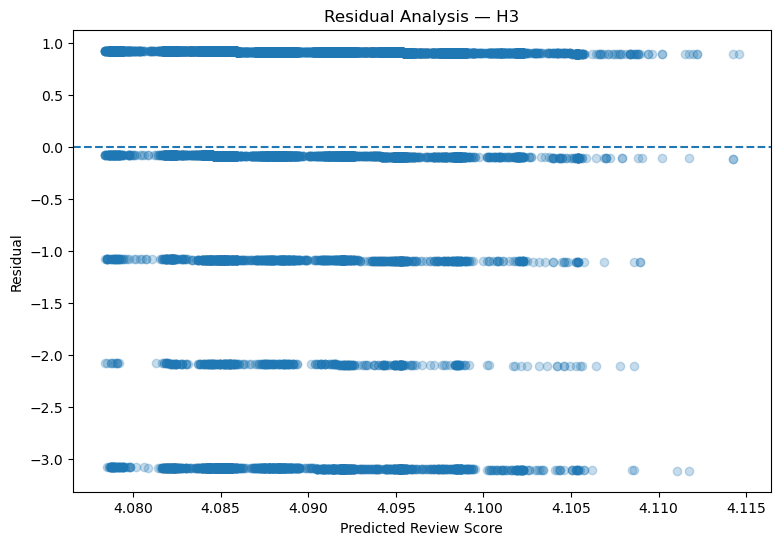

In [58]:
residuals = (
    H3['y_test']
    - H3['y_test_pred']
)

plt.figure(figsize=(9, 6))

plt.scatter(
    H3['y_test_pred'],
    residuals,
    alpha=0.25
)

plt.axhline(
    0,
    linestyle='--'
)

plt.xlabel("Predicted Review Score")
plt.ylabel("Residual")
plt.title("Residual Analysis — H3")

plt.show()

In [59]:
final_evaluation = results_table[
    [
        'Hypothesis',
        'X Variable',
        'Y Variable',
        'Test R²',
        'Test MAE',
        'Test RMSE'
    ]
].copy()

final_evaluation = final_evaluation.round(4)

display(final_evaluation)

,Hypothesis,X Variable,Y Variable,Test R²,Test MAE,Test RMSE
0,H2: Higher product prices improve review scores,unit_price,review_score,-0.0001,1.0458,1.3364
1,H3: Faster/on-time delivery improves customer ...,Delivery Delay,review_score,-0.0001,1.0370,1.3297
2,H4: Shorter fulfillment time improves review s...,Fulfillment Time,review_score,-0.0003,1.0770,1.3709
3,H5: Delivery delays increase customer churn,Delivery Delay,churn,0.0001,0.4988,0.4994
4,H6: Higher review scores increase reorder prob...,avg_review_score,reorder_rate,-0.0002,0.4998,0.4999
5,H7: Customer loyalty increases lifetime revenue,loyalty_score,lifetime_revenue,0.2738,12949.8964,22246.7865


In [60]:
print(
    f"Review Score = "
    f"{H3['Intercept']:.4f} + "
    f"({H3['Coefficient']:.6f} × Delivery Delay)"
)

Review Score = 4.0897 + (0.006150 × Delivery Delay)


In [61]:
coef = H3['Coefficient']
r2 = H3['Test R²']

print("BUSINESS INTERPRETATION")
print("-" * 60)

if coef > 0:
    print(
        "Delivery delay has a positive relationship "
        "with review score."
    )
elif coef < 0:
    print(
        "Delivery delay has a negative relationship "
        "with review score."
    )
else:
    print(
        "Delivery delay has no linear relationship "
        "with review score."
    )

if abs(r2) < 0.01:
    print(
        "However, the R² is extremely close to zero, "
        "so the model has negligible explanatory power."
    )
else:
    print(
        f"The model explains approximately "
        f"{r2 * 100:.2f}% of the variation in review scores."
    )

BUSINESS INTERPRETATION
------------------------------------------------------------
Delivery delay has a positive relationship with review score.
However, the R² is extremely close to zero, so the model has negligible explanatory power.
